<a href="https://colab.research.google.com/github/Abuabrar09/us-retail-financial-analysis/blob/main/US_Retail_Financial_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 US Retail Financial Statement Analysis — Walmart vs Target vs Costco
**Business & Financial Data Analyst | AI — Portfolio Project 2**

**Problem:** Which of America's biggest retailers is the most profitable, efficient and financially healthy?

**Data:** 4 years of annual income statements, balance sheets and cash flow statements from Yahoo Finance.

**Ratios analysed:** Gross, operating and net margin · ROE · ROA · Debt to equity · Current ratio · Inventory turnover · Free cash flow margin · Revenue growth

**Tools:** Python · pandas · matplotlib · yfinance

Loaded 12 company-years of data


,Company,Fiscal Year,Revenue ($B),Net Income ($B),Total Assets ($B)
11,Costco,2023,242.29,6.29,68.99
10,Costco,2024,254.45,7.37,69.83
9,Costco,2025,275.24,8.10,77.10
8,Costco,2026,303.15,9.23,89.05
7,Target,2023,109.12,2.78,53.34
6,Target,2024,107.41,4.14,55.36
5,Target,2025,106.57,4.09,57.77
4,Target,2026,104.78,3.71,59.49
3,Walmart,2023,611.29,11.68,243.20
2,Walmart,2024,648.12,15.51,252.40



LATEST-YEAR RATIO SCORECARD


Company,Costco,Target,Walmart
Gross Margin %,12.82,27.93,24.93
Operating Margin %,3.85,4.88,4.18
Net Margin %,3.04,3.54,3.07
ROE %,25.77,22.92,21.98
ROA %,10.36,6.23,7.69
Debt to Equity,0.24,1.26,0.67
Current Ratio,1.06,0.94,0.79
Inventory Turnover,13.68,6.14,9.10
Days Inventory,26.69,59.47,40.12
FCF Margin %,3.09,2.71,2.09


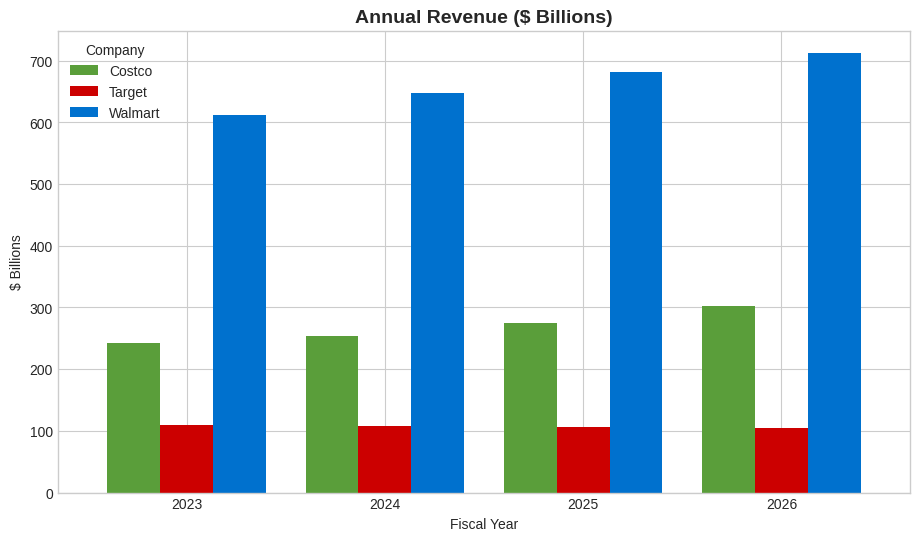

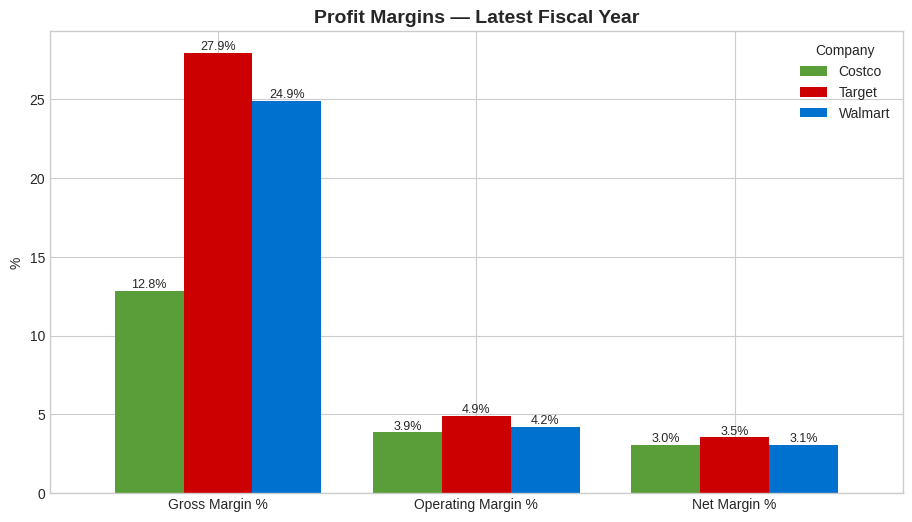

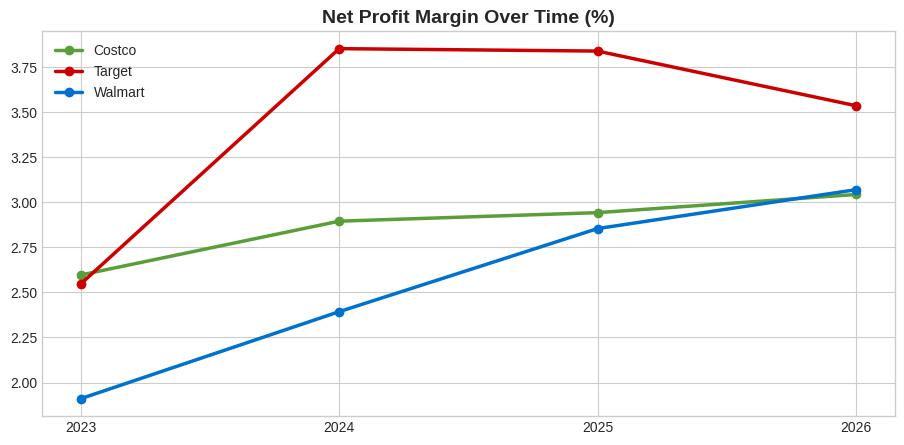

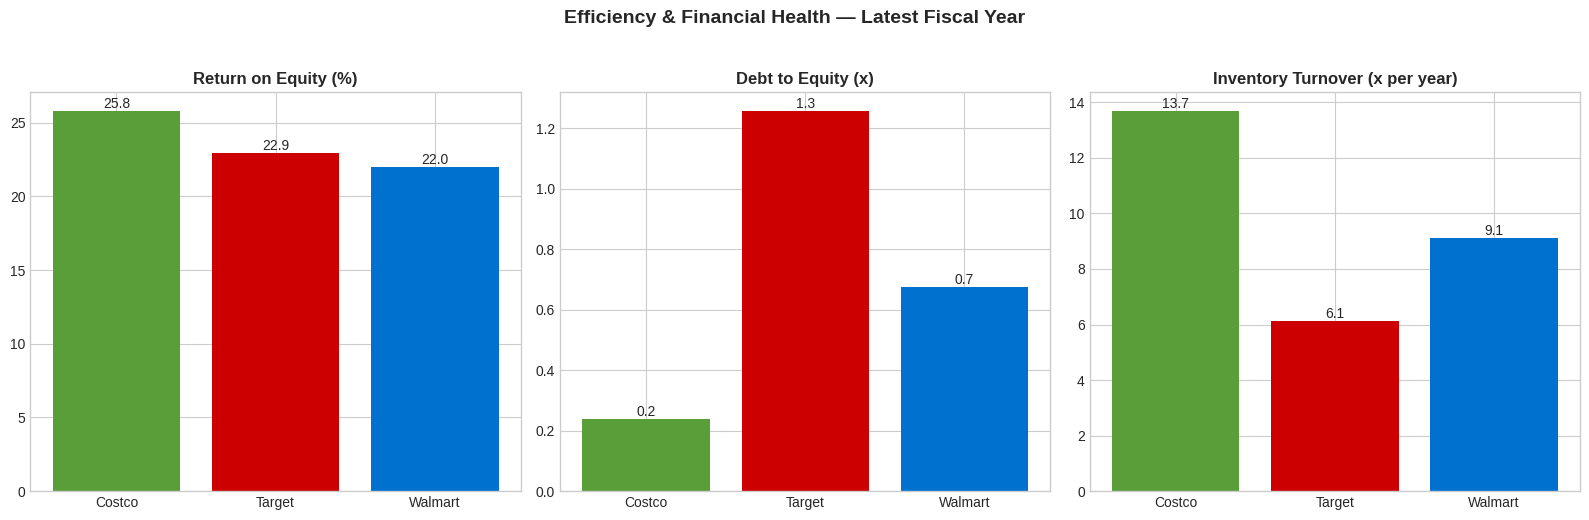


OVERALL RANKING (1 = best on each ratio)


,Gross Margin %,Operating Margin %,Net Margin %,ROE %,ROA %,Current Ratio,Inventory Turnover,FCF Margin %,Revenue Growth %,Debt to Equity,Average Rank
Company,,,,,,,,,,,
Costco,3.00,3.00,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.60
Target,1.00,1.00,1.00,2.00,3.00,2.00,3.00,2.00,3.00,3.00,2.10
Walmart,2.00,2.00,2.00,3.00,2.00,3.00,2.00,3.00,2.00,2.00,2.30



📌 KEY INSIGHTS

1. Biggest company: Walmart ($713B revenue).
2. Highest net margin: Target (3.54%); lowest: Costco (3.04%).
3. Highest gross margin: Target (27.9%) vs lowest Costco (12.8%).
4. Best return on equity: Costco (25.8%).
5. Fastest inventory turnover: Costco (13.7x/yr, ~27 days to sell stock).
6. Most debt: Target (debt/equity 1.26); least: Costco (0.24).
7. Fastest revenue growth: Costco (10.1% last year).
8. Overall best on these ratios: Costco (average rank 1.6).


In [3]:
# ===== 1. SETUP =====
!pip install -q yfinance
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.2f}".format)
plt.style.use("seaborn-v0_8-whitegrid")

companies = {"WMT": "Walmart", "TGT": "Target", "COST": "Costco"}
colors = {"Walmart": "#0071CE", "Target": "#CC0000", "Costco": "#5A9E3A"}

def get(df, names):
    """Return the first matching row from a financial statement (labels vary slightly)."""
    for n in names:
        if n in df.index:
            return df.loc[n]
    return pd.Series(np.nan, index=df.columns)

# ===== 2. DOWNLOAD FINANCIAL STATEMENTS =====
rows = []
for ticker, name in companies.items():
    t = yf.Ticker(ticker)
    inc, bal, cf = t.income_stmt, t.balance_sheet, t.cashflow
    df = pd.DataFrame({
        "Revenue": get(inc, ["Total Revenue", "Operating Revenue"]),
        "COGS": get(inc, ["Cost Of Revenue", "Reconciled Cost Of Revenue"]),
        "Gross Profit": get(inc, ["Gross Profit"]),
        "Operating Income": get(inc, ["Operating Income", "Total Operating Income As Reported"]),
        "Net Income": get(inc, ["Net Income", "Net Income Common Stockholders"]),
        "Total Assets": get(bal, ["Total Assets"]),
        "Equity": get(bal, ["Stockholders Equity", "Common Stock Equity"]),
        "Total Debt": get(bal, ["Total Debt"]),
        "Current Assets": get(bal, ["Current Assets"]),
        "Current Liabilities": get(bal, ["Current Liabilities"]),
        "Inventory": get(bal, ["Inventory"]),
        "Operating Cash Flow": get(cf, ["Operating Cash Flow"]),
        "Free Cash Flow": get(cf, ["Free Cash Flow"]),
    })
    df["Company"] = name
    df["Fiscal Year"] = pd.to_datetime(df.index).year
    rows.append(df)

fin = pd.concat(rows).dropna(subset=["Revenue", "Net Income"]).reset_index(drop=True)
fin = fin.sort_values(["Company", "Fiscal Year"])
print(f"Loaded {len(fin)} company-years of data")
display(fin[["Company", "Fiscal Year", "Revenue", "Net Income", "Total Assets"]].assign(
    Revenue=lambda d: d.Revenue / 1e9, **{"Net Income": lambda d: d["Net Income"] / 1e9,
    "Total Assets": lambda d: d["Total Assets"] / 1e9}).rename(columns={
    "Revenue": "Revenue ($B)", "Net Income": "Net Income ($B)", "Total Assets": "Total Assets ($B)"}))

# ===== 3. CALCULATE FINANCIAL RATIOS =====
fin["Gross Margin %"] = fin["Gross Profit"] / fin["Revenue"] * 100
fin["Operating Margin %"] = fin["Operating Income"] / fin["Revenue"] * 100
fin["Net Margin %"] = fin["Net Income"] / fin["Revenue"] * 100
fin["ROE %"] = fin["Net Income"] / fin["Equity"] * 100
fin["ROA %"] = fin["Net Income"] / fin["Total Assets"] * 100
fin["Debt to Equity"] = fin["Total Debt"] / fin["Equity"]
fin["Current Ratio"] = fin["Current Assets"] / fin["Current Liabilities"]
fin["Inventory Turnover"] = fin["COGS"] / fin["Inventory"]
fin["Days Inventory"] = 365 / fin["Inventory Turnover"]
fin["FCF Margin %"] = fin["Free Cash Flow"] / fin["Revenue"] * 100
fin["Revenue Growth %"] = fin.groupby("Company")["Revenue"].pct_change() * 100

latest = fin.sort_values("Fiscal Year").groupby("Company").tail(1).set_index("Company")
ratio_cols = [ "Gross Margin %", "Operating Margin %", "Net Margin %", "ROE %", "ROA %",
              "Debt to Equity", "Current Ratio", "Inventory Turnover", "Days Inventory", "FCF Margin %", "Revenue Growth %"]
print("\nLATEST-YEAR RATIO SCORECARD")
display(latest[ratio_cols].T)

# ===== 4. REVENUE TREND =====
pivot_rev = fin.pivot(index="Fiscal Year", columns="Company", values="Revenue") / 1e9
ax = pivot_rev.plot(kind="bar", figsize=(11, 6), color=[colors[c] for c in pivot_rev.columns], width=0.8)
ax.set_title("Annual Revenue ($ Billions)", fontsize=14, weight="bold")
ax.set_ylabel("$ Billions"); ax.set_xlabel("Fiscal Year"); plt.xticks(rotation=0); plt.show()

# ===== 5. PROFITABILITY — MARGINS =====
margins = latest[["Gross Margin %", "Operating Margin %", "Net Margin %"]]
ax = margins.T.plot(kind="bar", figsize=(11, 6), color=[colors[c] for c in margins.index], width=0.8)
ax.set_title("Profit Margins — Latest Fiscal Year", fontsize=14, weight="bold")
ax.set_ylabel("%"); plt.xticks(rotation=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f%%", fontsize=9)
plt.show()

# ===== 6. NET MARGIN TREND =====
fig, ax = plt.subplots(figsize=(11, 5))
for c, g in fin.groupby("Company"):
    ax.plot(g["Fiscal Year"], g["Net Margin %"], marker="o", linewidth=2.5, label=c, color=colors[c])
ax.set_title("Net Profit Margin Over Time (%)", fontsize=14, weight="bold")
ax.set_xticks(sorted(fin["Fiscal Year"].unique())); ax.legend(); plt.show()

# ===== 7. RETURNS, DEBT & EFFICIENCY =====
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, title in zip(axes, ["ROE %", "Debt to Equity", "Inventory Turnover"],
                          ["Return on Equity (%)", "Debt to Equity (x)", "Inventory Turnover (x per year)"]):
    vals = latest[col]
    bars = ax.bar(vals.index, vals.values, color=[colors[c] for c in vals.index])
    ax.bar_label(bars, fmt="%.1f", fontsize=10)
    ax.set_title(title, fontsize=12, weight="bold")
plt.suptitle("Efficiency & Financial Health — Latest Fiscal Year", fontsize=14, weight="bold", y=1.03)
plt.tight_layout(); plt.show()

# ===== 8. OVERALL RANKING =====
higher_better = ["Gross Margin %", "Operating Margin %", "Net Margin %", "ROE %", "ROA %",
                 "Current Ratio", "Inventory Turnover", "FCF Margin %", "Revenue Growth %"]
lower_better = ["Debt to Equity"]
ranks = pd.concat([latest[higher_better].rank(ascending=False),
                   latest[lower_better].rank(ascending=True)], axis=1)
ranks["Average Rank"] = ranks.mean(axis=1)
ranks = ranks.sort_values("Average Rank")
print("\nOVERALL RANKING (1 = best on each ratio)")
display(ranks)

# ===== 9. KEY INSIGHTS =====
L = latest
print("\n📌 KEY INSIGHTS\n")
print(f"1. Biggest company: {L['Revenue'].idxmax()} (${L['Revenue'].max()/1e9:,.0f}B revenue).")
print(f"2. Highest net margin: {L['Net Margin %'].idxmax()} ({L['Net Margin %'].max():.2f}%); lowest: {L['Net Margin %'].idxmin()} ({L['Net Margin %'].min():.2f}%).")
print(f"3. Highest gross margin: {L['Gross Margin %'].idxmax()} ({L['Gross Margin %'].max():.1f}%) vs lowest {L['Gross Margin %'].idxmin()} ({L['Gross Margin %'].min():.1f}%).")
print(f"4. Best return on equity: {L['ROE %'].idxmax()} ({L['ROE %'].max():.1f}%).")
print(f"5. Fastest inventory turnover: {L['Inventory Turnover'].idxmax()} ({L['Inventory Turnover'].max():.1f}x/yr, ~{L['Days Inventory'].min():.0f} days to sell stock).")
print(f"6. Most debt: {L['Debt to Equity'].idxmax()} (debt/equity {L['Debt to Equity'].max():.2f}); least: {L['Debt to Equity'].idxmin()} ({L['Debt to Equity'].min():.2f}).")
print(f"7. Fastest revenue growth: {L['Revenue Growth %'].idxmax()} ({L['Revenue Growth %'].max():.1f}% last year).")
print(f"8. Overall best on these ratios: {ranks.index[0]} (average rank {ranks['Average Rank'].iloc[0]:.1f}).")

## 📝 Conclusion
**Costco is the strongest business overall**, ranking #1 on 7 of 10 ratios, despite having the **lowest gross margin (12.8%)**, less than half of Target's (27.9%). Its secret is speed: Costco sells its entire inventory in about **27 days**, compared with 40 days at Walmart and 59 days at Target. Turning stock over quickly, combined with very little debt (debt/equity 0.24), gives Costco the best return on equity (25.8%) and the fastest growth (10.1%).

**Target** earns the highest margins, but it carries the most debt (1.26) and its revenue shrank last year (−1.7%). **Walmart** is by far the biggest company ($713B revenue) and sits in the middle on most ratios.

**Business lesson:** in retail, high margins alone don't win. Selling fast with low costs and low debt creates more value for shareholders.